In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Fijar semillas para favorecer la reproducibilidad
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Librerías importadas correctamente.")


TensorFlow: 2.21.0
Librerías importadas correctamente.


In [2]:

# Cargar el conjunto de datos MNIST
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

# Mostrar las dimensiones de los datos
print("Train original:", x_train_full.shape, y_train_full.shape)
print("Test:", x_test.shape, y_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train original: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)


In [3]:

# Dividir los datos de entrenamiento en Train y Dev
x_train, x_dev, y_train, y_dev = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

# Mostrar las dimensiones de cada conjunto
print("Train:", x_train.shape, y_train.shape)
print("Dev:", x_dev.shape, y_dev.shape)
print("Test:", x_test.shape, y_test.shape)


Train: (48000, 28, 28) (48000,)
Dev: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)


In [4]:

# Normalizar las imágenes de los tres conjuntos
x_train = x_train.astype("float32") / 255.0
x_dev = x_dev.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Verificar el rango de los píxeles
print("Rango train:", x_train.min(), x_train.max())
print("Rango dev:", x_dev.min(), x_dev.max())
print("Rango test:", x_test.min(), x_test.max())


Rango train: 0.0 1.0
Rango dev: 0.0 1.0
Rango test: 0.0 1.0


In [5]:

# Función para calcular la distribución de las clases
def distribucion_clases(y, nombre):
    conteos = np.bincount(y, minlength=10)
    porcentajes = conteos / len(y) * 100

    tabla = pd.DataFrame({
        "digito": np.arange(10),
        "cantidad": conteos,
        "porcentaje": np.round(porcentajes, 2)
    })

    print("\n", nombre)
    display(tabla)

    return tabla

# Calcular la distribución en cada conjunto
dist_train = distribucion_clases(y_train, "TRAIN")
dist_dev = distribucion_clases(y_dev, "DEV")
dist_test = distribucion_clases(y_test, "TEST")



 TRAIN


,digito,cantidad,porcentaje
0,0,4738,9.87
1,1,5394,11.24
2,2,4766,9.93
3,3,4905,10.22
4,4,4674,9.74
5,5,4337,9.04
6,6,4734,9.86
7,7,5012,10.44
8,8,4681,9.75
9,9,4759,9.91



 DEV


,digito,cantidad,porcentaje
0,0,1185,9.88
1,1,1348,11.23
2,2,1192,9.93
3,3,1226,10.22
4,4,1168,9.73
5,5,1084,9.03
6,6,1184,9.87
7,7,1253,10.44
8,8,1170,9.75
9,9,1190,9.92



 TEST


,digito,cantidad,porcentaje
0,0,980,9.80
1,1,1135,11.35
2,2,1032,10.32
3,3,1010,10.10
4,4,982,9.82
5,5,892,8.92
6,6,958,9.58
7,7,1028,10.28
8,8,974,9.74
9,9,1009,10.09


In [6]:

# Función para crear el modelo baseline
def crear_modelo_baseline(units=128, optimizer=None):
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(units, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    if optimizer is None:
        optimizer = keras.optimizers.Adam(learning_rate=0.001)

    modelo.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return modelo

# Crear el modelo
modelo_base = crear_modelo_baseline()

# Mostrar la arquitectura de la red
modelo_base.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:

# Entrenar el modelo baseline
hist_base = modelo_base.fit(
    x_train,
    y_train,
    validation_data=(x_dev, y_dev),
    epochs=5,
    batch_size=64,
    verbose=1
)


Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9084 - loss: 0.3258 - val_accuracy: 0.9447 - val_loss: 0.1930
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9578 - loss: 0.1462 - val_accuracy: 0.9563 - val_loss: 0.1502
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9699 - loss: 0.1029 - val_accuracy: 0.9613 - val_loss: 0.1309
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9772 - loss: 0.0783 - val_accuracy: 0.9634 - val_loss: 0.1219
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9823 - loss: 0.0615 - val_accuracy: 0.9645 - val_loss: 0.1164


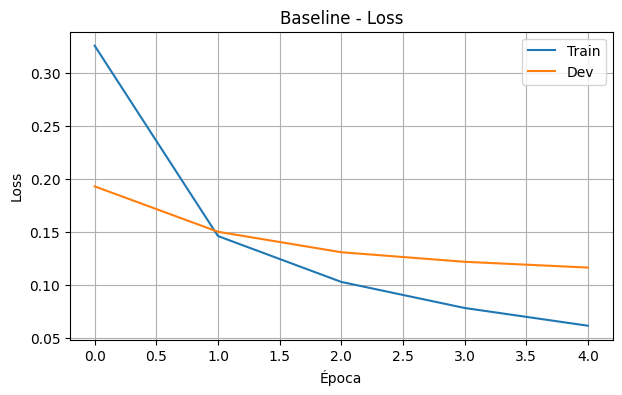

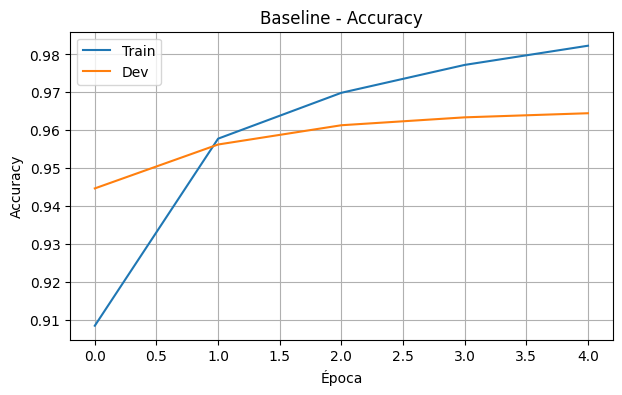

In [8]:

# Gráfica 1: Loss
plt.figure(figsize=(7, 4))
plt.plot(hist_base.history["loss"], label="Train")
plt.plot(hist_base.history["val_loss"], label="Dev")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Baseline - Loss")
plt.legend()
plt.grid(True)
plt.show()

# Gráfica 2: Accuracy
plt.figure(figsize=(7, 4))
plt.plot(hist_base.history["accuracy"], label="Train")
plt.plot(hist_base.history["val_accuracy"], label="Dev")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.title("Baseline - Accuracy")
plt.legend()
plt.grid(True)
plt.show()
